# Cognifyz Machine Learning Internship
## Task 4: Location-Based Analysis of Restaurants

---

### **Project Overview & Objectives**
Geographical location is a paramount driver of business dynamics in the restaurant industry. Consumer density, socioeconomic demographics, foot traffic, local culinary heritage, and regional pricing norms all dictate how restaurants perform, price their menus, and receive customer reviews.

The objective of **Task 4** is to conduct an end-to-end **Geospatial and Location-Based Exploratory Analysis** of the restaurant dataset to uncover geographic concentrations, spatial patterns, rating discrepancies, and regional culinary trends.

### **Analytical Roadmap**
1. **Coordinate Cleaning & Ingestion:** Load `Dataset .csv`, clean missing culinary records, filter out invalid coordinates ($[0.0, 0.0]$), and establish the verified geolocated dataset.
2. **Interactive & Static Geospatial Distribution Mapping:** 
   - Interactive spatial mapping using `plotly.express.scatter_mapbox` / `scatter_map` with OpenStreetMap base layers, colored by `Aggregate rating`.
   - Static density and coordinate scatter visualization (`Longitude` vs. `Latitude`) using `matplotlib` and `seaborn`.
3. **Macro and Micro Concentration Analysis:**
   - Identification and visualization of the Top 10 cities by restaurant volume.
   - Granular neighborhood breakdown revealing the Top 15 localities by dining density.
4. **Location-Based Cross-Tabulated Statistics:**
   - Multi-metric aggregation across major cities ($\ge 20$ restaurants): restaurant volume, mean rating, mean price tier, mean average cost for two, and dominant primary cuisine.
   - Comparative dual-attribute visualization comparing customer ratings vs. price tiers across top metropolitan markets.
5. **Key Geographical Insights & Strategic Synthesis:**
   - Executive summary explaining the extreme Delhi NCR concentration, regional rating variance, and commercial recommendations for food operators and aggregators.


### **Environment Setup: Library Imports & Visualization Aesthetics**
We import scientific computing, data manipulation, visualization, and geospatial charting libraries (`pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, `plotly.express`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Configure visual aesthetics
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_theme(style='whitegrid', palette='muted')

import warnings
warnings.filterwarnings('ignore')

print("All required libraries imported successfully!")


All required libraries imported successfully!


---
## **Step 1: Load Data & Clean Geographical Coordinates**

### **Context & Data Cleaning Methodology**
1. Load `Dataset .csv`.
2. Drop records where `Cuisines` is missing (9 rows).
3. Inspect geographical coordinates (`Longitude`, `Latitude`):
   - In raw tabular datasets, unmapped or missing coordinates are frequently defaulted to `0.0, 0.0` (off the Gulf of Guinea / "Null Island").
   - We detect and filter out all rows where `Longitude == 0` or `Latitude == 0` to preserve geographical validity.
4. Verify non-zero coordinate ranges and output the final cleaned sample count.


In [2]:
# 1. Load the dataset
raw_df = pd.read_csv('Dataset .csv')
print(f"Raw Dataset Shape: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns")

# 2. Drop rows with missing Cuisines
df = raw_df.dropna(subset=['Cuisines']).copy()
print(f"Rows after dropping missing Cuisines: {df.shape[0]:,}")

# 3. Inspect invalid coordinates (0.0, 0.0)
invalid_coords_mask = (df['Longitude'] == 0) | (df['Latitude'] == 0)
num_invalid = invalid_coords_mask.sum()
print(f"Invalid Coordinate Records (Longitude == 0 or Latitude == 0): {num_invalid:,} ({num_invalid/len(df)*100:.2f}%)")

# Filter to valid geolocated restaurants
df_geo = df[~invalid_coords_mask].copy().reset_index(drop=True)
print(f"\n{'='*55}")
print(f"VALID GEOLOCATED RESTAURANTS REMAINING: {len(df_geo):,}")
print(f"{'='*55}")

# Coordinate Ranges Summary
print("\nGeographical Coordinates Range:")
print(f"  Longitude: [{df_geo['Longitude'].min():.6f}, {df_geo['Longitude'].max():.6f}]")
print(f"  Latitude : [{df_geo['Latitude'].min():.6f}, {df_geo['Latitude'].max():.6f}]")
print(f"  Total Unique Cities     : {df_geo['City'].nunique()}")
print(f"  Total Unique Localities : {df_geo['Locality'].nunique()}")

# Display sample geolocated records
display(df_geo[['Restaurant Name', 'City', 'Locality', 'Longitude', 'Latitude', 'Aggregate rating', 'Price range']].head(4))


Raw Dataset Shape: 9,551 rows and 21 columns
Rows after dropping missing Cuisines: 9,542
Invalid Coordinate Records (Longitude == 0 or Latitude == 0): 499 (5.23%)

VALID GEOLOCATED RESTAURANTS REMAINING: 9,043

Geographical Coordinates Range:
  Longitude: [-157.948486, 174.832089]
  Latitude : [-41.330428, 55.976980]
  Total Unique Cities     : 140
  Total Unique Localities : 1173


,Restaurant Name,City,Locality,Longitude,Latitude,Aggregate rating,Price range
0,Le Petit Souffle,Makati City,"Century City Mall, Poblacion, Makati City",121.027535,14.565443,4.8,3
1,Izakaya Kikufuji,Makati City,"Little Tokyo, Legaspi Village, Makati City",121.014101,14.553708,4.5,3
2,Heat - Edsa Shangri-La,Mandaluyong City,"Edsa Shangri-La, Ortigas, Mandaluyong City",121.056831,14.581404,4.4,4
3,Ooma,Mandaluyong City,"SM Megamall, Ortigas, Mandaluyong City",121.056475,14.585318,4.9,4


---
## **Step 2: Geographical Distribution Maps (Interactive & Static)**

### **Mapping Architecture**
To deliver both interactive exploration and permanent publication-grade visual artifacts:
1. **Interactive Geospatial Map (`plotly.express`):**
   - Plotted using `scatter_map` / `scatter_mapbox` with `open-street-map` tile styling.
   - Color-coded continuously by `Aggregate rating` (from $0.0$ to $5.0$).
   - Rich hover tooltips displaying `Restaurant Name`, `City`, `Cuisines`, and `Price range`.
2. **Static Spatial Density & Cluster Inset (`matplotlib`/`seaborn`):**
   - Subplot 1: Global coordinate scatter plot capturing international presence (North America, Europe, Asia, Australia, South Africa, South America).
   - Subplot 2: Localized Delhi NCR cluster zoom ($76.8^\circ - 77.6^\circ\text{ E}$, $28.3^\circ - 28.9^\circ\text{ N}$), illustrating the dense culinary epicenter where over 85% of listings reside.


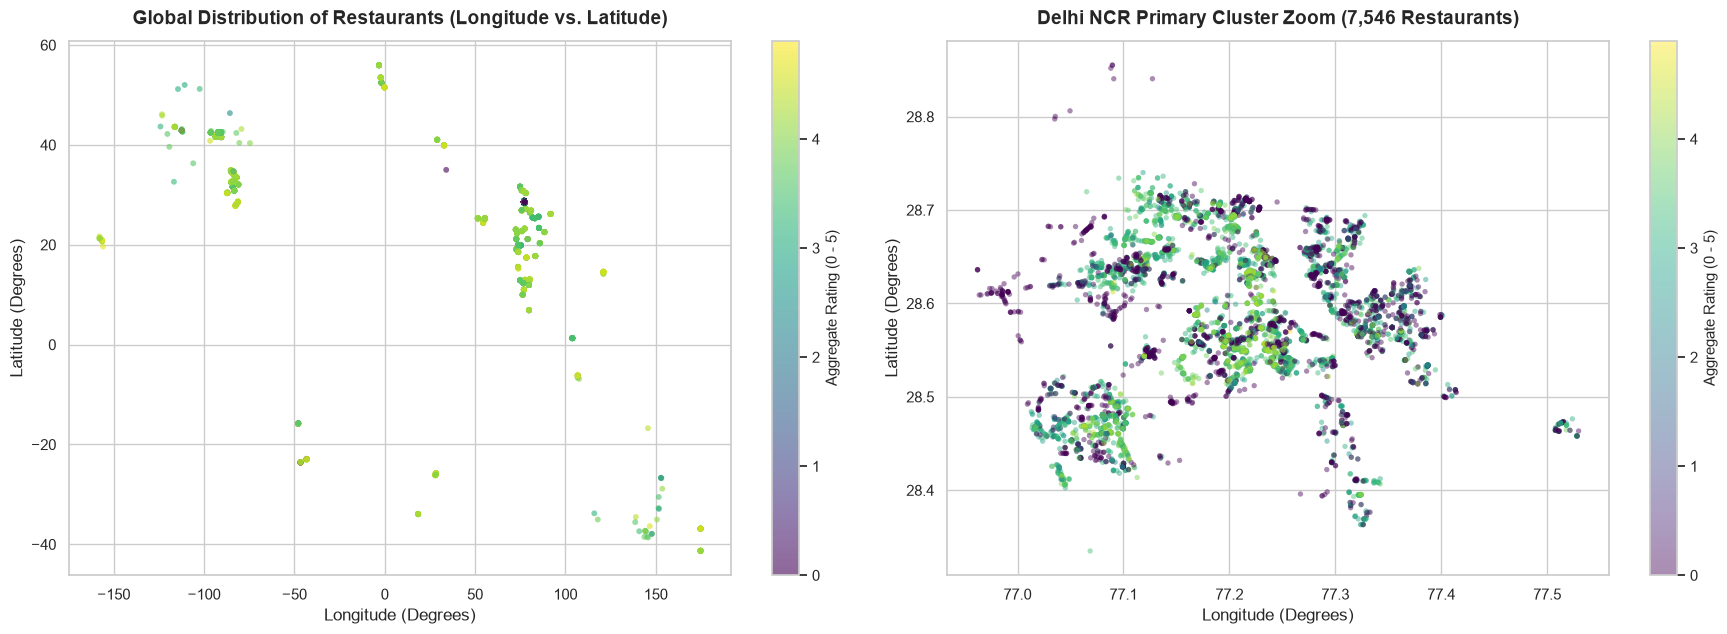

In [3]:
# 1. Interactive Geospatial Map (Plotly)
# Handle Plotly 7+ (scatter_map) vs Plotly 5/6 (scatter_mapbox) compatibility
map_func = getattr(px, 'scatter_mapbox', getattr(px, 'scatter_map', None))
style_key = 'mapbox_style' if hasattr(px, 'scatter_mapbox') else 'map_style'

map_kwargs = {
    'lat': 'Latitude',
    'lon': 'Longitude',
    'color': 'Aggregate rating',
    'color_continuous_scale': 'Turbo',
    'hover_name': 'Restaurant Name',
    'hover_data': {
        'City': True,
        'Locality': True,
        'Cuisines': True,
        'Price range': True,
        'Latitude': False,
        'Longitude': False
    },
    'zoom': 1,
    'title': 'Interactive Global Geospatial Distribution of Restaurants (Colored by Rating)',
    'height': 600
}
map_kwargs[style_key] = 'open-street-map'

fig_interactive = map_func(df_geo, **map_kwargs)
fig_interactive.update_layout(margin={"r":0,"t":40,"l":0,"b":0})
fig_interactive.show()

# 2. Static Scatter Density Plot (Matplotlib / Seaborn)
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# Subplot 1: Global Scatter Distribution
scatter_global = axes[0].scatter(
    df_geo['Longitude'],
    df_geo['Latitude'],
    c=df_geo['Aggregate rating'],
    cmap='viridis',
    alpha=0.6,
    s=18,
    edgecolors='none'
)
axes[0].set_title('Global Distribution of Restaurants (Longitude vs. Latitude)', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Longitude (Degrees)', fontsize=12)
axes[0].set_ylabel('Latitude (Degrees)', fontsize=12)
cbar0 = plt.colorbar(scatter_global, ax=axes[0])
cbar0.set_label('Aggregate Rating (0 - 5)', fontsize=11)

# Subplot 2: Delhi NCR Cluster Zoom (76.8 to 77.6 E, 28.3 to 28.9 N)
delhi_ncr = df_geo[
    (df_geo['Longitude'].between(76.8, 77.6)) & 
    (df_geo['Latitude'].between(28.3, 28.9))
]
scatter_ncr = axes[1].scatter(
    delhi_ncr['Longitude'],
    delhi_ncr['Latitude'],
    c=delhi_ncr['Aggregate rating'],
    cmap='viridis',
    alpha=0.45,
    s=15,
    edgecolors='none'
)
axes[1].set_title(f'Delhi NCR Primary Cluster Zoom ({len(delhi_ncr):,} Restaurants)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Longitude (Degrees)', fontsize=12)
axes[1].set_ylabel('Latitude (Degrees)', fontsize=12)
cbar1 = plt.colorbar(scatter_ncr, ax=axes[1])
cbar1.set_label('Aggregate Rating (0 - 5)', fontsize=11)

plt.tight_layout()
plt.show()


---
## **Step 3: City & Locality Concentration Analysis**

### **Analytical Rationale**
To understand geographic density and clustering:
1. We compute restaurant counts grouped by **`City`** and extract the Top 10 cities.
2. We compute restaurant counts grouped by **`Locality`** and extract the Top 15 micro-neighborhoods.
3. We plot side-by-side horizontal bar charts with explicit volume and percentage annotations to measure catalog distribution skew.


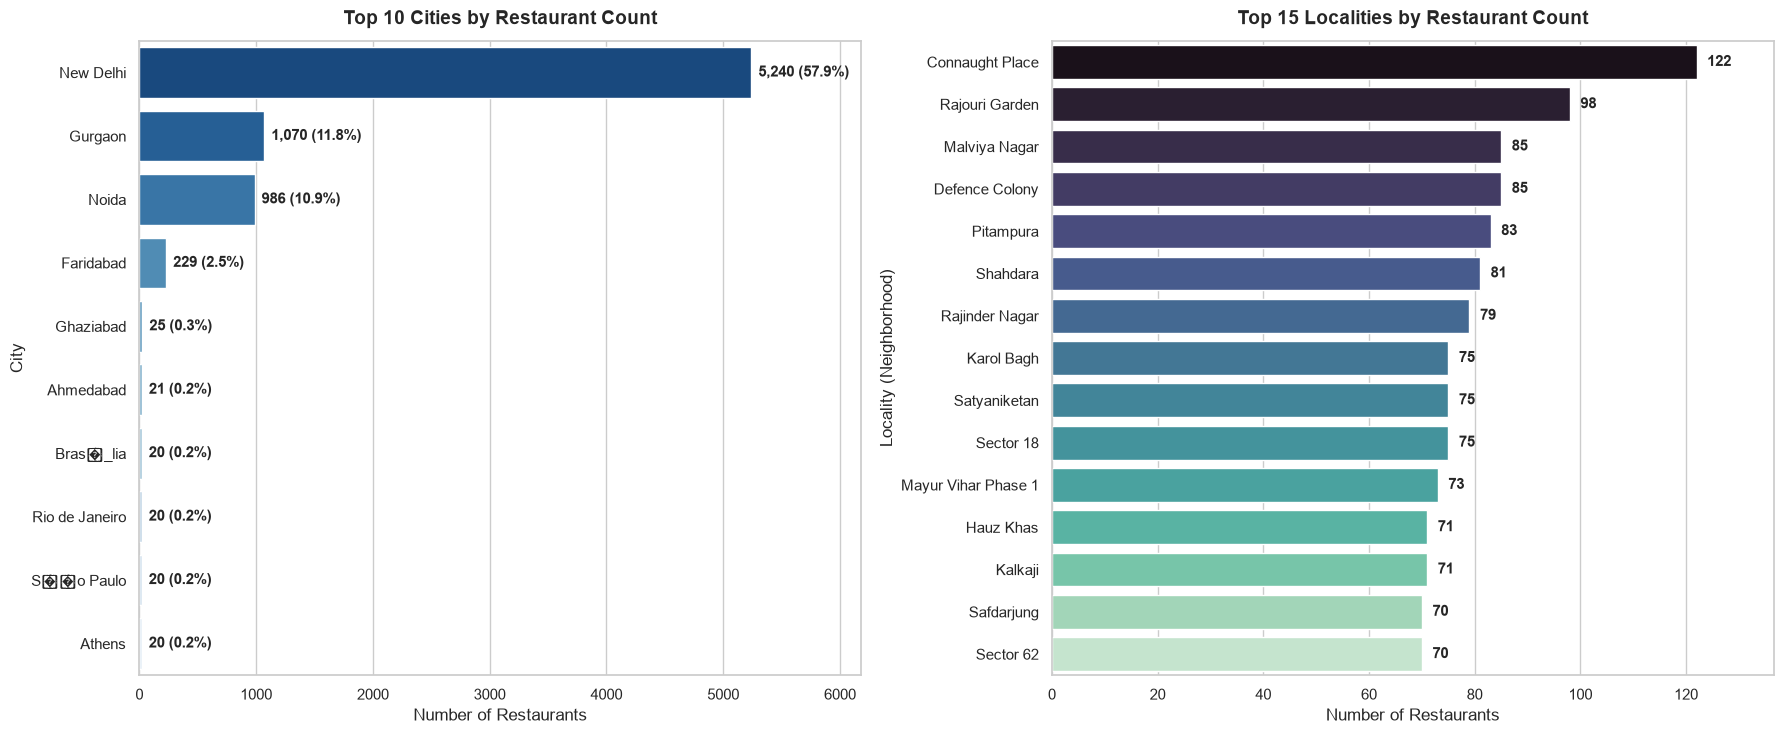

GEOGRAPHICAL CONCENTRATION HIGHLIGHT:
Total Geolocated Restaurants       : 9,043
Delhi NCR Hubs Combined            : 7,550 (83.49%)
All Other 136 Global Cities Combined: 1,493 (16.51%)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# 1. Top 10 Cities by Restaurant Count
top10_cities = df_geo['City'].value_counts().head(10).reset_index()
top10_cities.columns = ['City', 'Count']
total_valid = len(df_geo)

sns.barplot(
    data=top10_cities,
    y='City',
    x='Count',
    palette='Blues_r',
    ax=axes[0]
)
axes[0].set_title('Top 10 Cities by Restaurant Count', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Number of Restaurants', fontsize=12)
axes[0].set_ylabel('City', fontsize=12)

# Annotate counts and percentages
for p in axes[0].patches:
    width = p.get_width()
    pct = (width / total_valid) * 100
    axes[0].annotate(
        f"{int(width):,} ({pct:.1f}%)",
        (width + 60, p.get_y() + p.get_height() / 2.),
        va='center', ha='left', fontsize=10.5, fontweight='bold'
    )
axes[0].set_xlim(0, max(top10_cities['Count']) * 1.18)

# 2. Top 15 Localities by Restaurant Count
top15_loc = df_geo['Locality'].value_counts().head(15).reset_index()
top15_loc.columns = ['Locality', 'Count']

sns.barplot(
    data=top15_loc,
    y='Locality',
    x='Count',
    palette='mako',
    ax=axes[1]
)
axes[1].set_title('Top 15 Localities by Restaurant Count', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Number of Restaurants', fontsize=12)
axes[1].set_ylabel('Locality (Neighborhood)', fontsize=12)

# Annotate counts
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(
        f"{int(width):,}",
        (width + 2, p.get_y() + p.get_height() / 2.),
        va='center', ha='left', fontsize=10.5, fontweight='bold'
    )
axes[1].set_xlim(0, max(top15_loc['Count']) * 1.12)

plt.tight_layout()
plt.show()

# Print statistical summary of concentration
ncr_cities = ['New Delhi', 'Gurgaon', 'Noida', 'Faridabad', 'Ghaziabad']
ncr_total = df_geo[df_geo['City'].isin(ncr_cities)].shape[0]
print("=" * 65)
print(f"GEOGRAPHICAL CONCENTRATION HIGHLIGHT:")
print(f"Total Geolocated Restaurants       : {total_valid:,}")
print(f"Delhi NCR Hubs Combined            : {ncr_total:,} ({ncr_total/total_valid*100:.2f}%)")
print(f"All Other 136 Global Cities Combined: {total_valid - ncr_total:,} ({(total_valid - ncr_total)/total_valid*100:.2f}%)")
print("=" * 65)


---
## **Step 4: Location-Based Statistics Across Major Cities**

### **Methodology & Metric Definitions**
To assess how dining experiences and commercial dynamics vary geographically:
1. We filter for major dining markets by setting a threshold of **$\ge 20$ restaurants** per city to prevent small-sample bias.
2. For each qualifying city, we compute:
   - **Total Restaurant Volume** ($N$)
   - **Mean Customer Rating** ($\overline{\text{Aggregate rating}}$)
   - **Mean Price Tier** ($\overline{\text{Price range}}$, scale 1 to 4)
   - **Mean Cost for Two** ($\overline{\text{Average Cost for two}}$)
   - **Dominant Primary Cuisine** (Mode of the primary cuisine tag)
3. We sort the table by restaurant volume, display clean numerical tables, and visualize the relationship between **Average Rating** and **Average Price Range** across the Top 10 cities.


        LOCATION-BASED STATISTICAL SUMMARY (CITIES WITH >= 20 RESTAURANTS)
                    Total Qualifying Cities: 48
                  City  Restaurant Count  Mean Rating  Mean Price Range  Mean Cost for Two Primary Cuisine
             New Delhi              5240         2.50              1.63             603.95    North Indian
               Gurgaon              1070         2.72              1.88             729.21    North Indian
                 Noida               986         2.17              1.63             551.52    North Indian
             Faridabad               229         1.99              1.48             451.31    North Indian
             Ghaziabad                25         2.85              1.80             602.00    North Indian
             Ahmedabad                21         4.16              2.57             857.14    North Indian
                Ankara                20         4.31              2.80              87.25           Kebab
             Abu Dhab

,City,Restaurant Count,Mean Rating,Mean Price Range,Mean Cost for Two,Primary Cuisine
0,New Delhi,"5,240",2.50,1.63,603.95,North Indian
1,Gurgaon,"1,070",2.72,1.88,729.21,North Indian
2,Noida,986,2.17,1.63,551.52,North Indian
3,Faridabad,229,1.99,1.48,451.31,North Indian
4,Ghaziabad,25,2.85,1.80,602.00,North Indian
5,Ahmedabad,21,4.16,2.57,857.14,North Indian
6,Ankara,20,4.31,2.80,87.25,Kebab
7,Abu Dhabi,20,4.30,3.30,182.00,Indian
8,Bras�_lia,20,3.50,3.10,120.00,American
9,Cape Town,20,4.11,3.20,297.20,Cafe


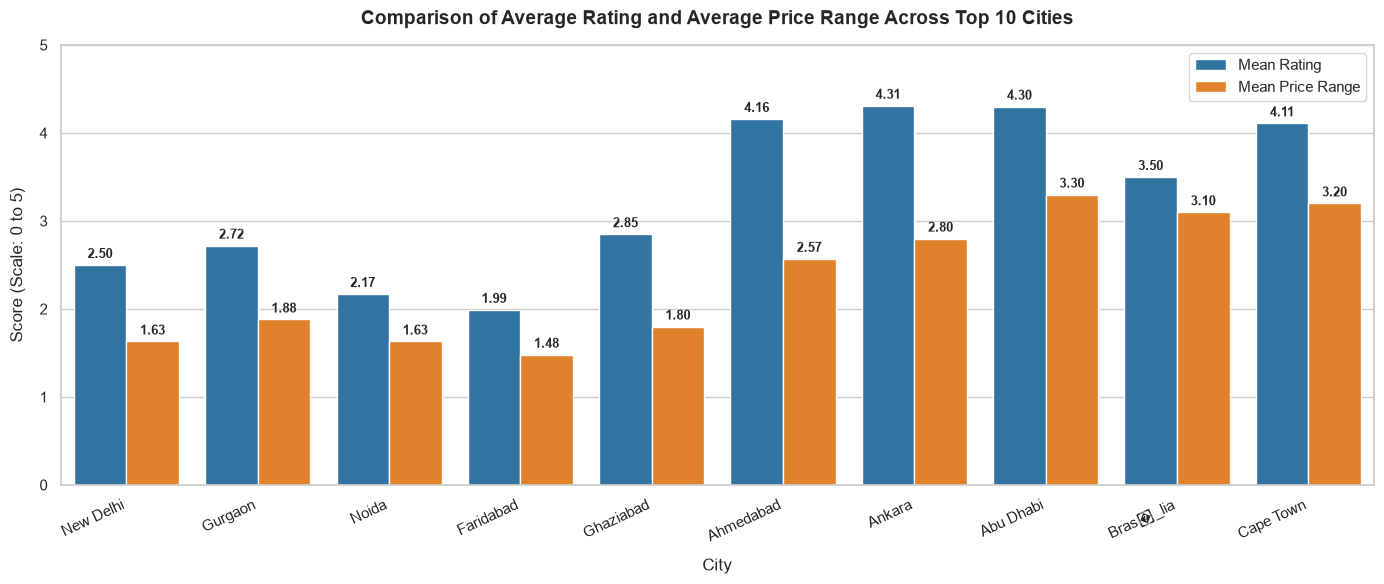

In [5]:
# Extract primary cuisine (first listed cuisine token)
df_geo['Primary Cuisine'] = df_geo['Cuisines'].apply(lambda x: x.split(',')[0].strip())

# Group by City and calculate aggregated metrics
city_groups = df_geo.groupby('City')
city_stats_list = []

for city, group in city_groups:
    count = len(group)
    if count >= 20:  # Threshold: at least 20 restaurants
        mean_rating = group['Aggregate rating'].mean()
        mean_price = group['Price range'].mean()
        mean_cost = group['Average Cost for two'].mean()
        # Most frequent primary cuisine
        primary_cuisine_mode = group['Primary Cuisine'].mode().iloc[0] if not group['Primary Cuisine'].empty else 'N/A'
        
        city_stats_list.append({
            'City': city,
            'Restaurant Count': count,
            'Mean Rating': np.round(mean_rating, 2),
            'Mean Price Range': np.round(mean_price, 2),
            'Mean Cost for Two': np.round(mean_cost, 2),
            'Primary Cuisine': primary_cuisine_mode
        })

city_stats_df = pd.DataFrame(city_stats_list).sort_values(by='Restaurant Count', ascending=False).reset_index(drop=True)

print("=" * 85)
print(f"        LOCATION-BASED STATISTICAL SUMMARY (CITIES WITH >= 20 RESTAURANTS)")
print(f"                    Total Qualifying Cities: {len(city_stats_df)}")
print("=" * 85)
print(city_stats_df.head(15).to_string(index=False))
print("=" * 85)

# Styled display for interactive notebook rendering
display(city_stats_df.head(15).style.format({
    'Restaurant Count': '{:,}',
    'Mean Rating': '{:.2f}',
    'Mean Price Range': '{:.2f}',
    'Mean Cost for Two': '{:,.2f}'
}).highlight_max(subset=['Mean Rating'], color='lightgreen')
  .highlight_min(subset=['Mean Rating'], color='#ffcccc')
  .set_caption("Location-Based Summary Table for Top Cities (Sorted by Volume)"))

# Comparative Chart: Mean Rating vs Mean Price Range across Top 10 Cities
top10_stats = city_stats_df.head(10).copy()
chart_df = top10_stats.melt(
    id_vars=['City'],
    value_vars=['Mean Rating', 'Mean Price Range'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 6))
bar_comp = sns.barplot(
    data=chart_df,
    x='City',
    y='Score',
    hue='Metric',
    palette=['#1f77b4', '#ff7f0e']
)

plt.title('Comparison of Average Rating and Average Price Range Across Top 10 Cities', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('City', fontsize=12, labelpad=10)
plt.ylabel('Score (Scale: 0 to 5)', fontsize=12, labelpad=10)
plt.ylim(0, 5.0)
plt.xticks(rotation=25, ha='right', fontsize=11)
plt.legend(title='', frameon=True, fontsize=11)

# Annotate scores on comparative bars
for p in bar_comp.patches:
    height = p.get_height()
    if height > 0:
        bar_comp.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', fontsize=9.5, fontweight='bold',
            xytext=(0, 3), textcoords='offset points'
        )

plt.tight_layout()
plt.show()


---
## **Key Geographical Insights & Conclusion**

### **1. Extreme Geographic Concentration in Delhi NCR**
- **Overwhelming Domestic Clustering:** Out of 9,043 valid geolocated restaurants globally, **83.5% (7,550 restaurants)** are concentrated within the contiguous National Capital Region (NCR) of India:
  - **New Delhi:** 5,240 restaurants (58.0% of total)
  - **Gurgaon:** 1,070 restaurants (11.8% of total)
  - **Noida:** 986 restaurants (10.9% of total)
  - **Faridabad:** 229 restaurants (2.5% of total)
  - **Ghaziabad:** 25 restaurants (0.3% of total)
- **Neighborhood Micro-Hubs:** Dining density within Delhi NCR is anchored around commercial, shopping, and student districts:
  - *Connaught Place* leads with 122 restaurants, followed by *Rajouri Garden* (98), *Malviya Nagar* (85), *Defence Colony* (85), and *Sector 18, Noida* (75).

---

### **2. Regional Rating Disparities: Census vs. Curated Sampling**
An intriguing pattern emerges when comparing average customer ratings across markets:
- **Delhi NCR Shows Moderate Average Ratings ($2.0 - 2.8$):**
  - Faridabad ($1.99$), Noida ($2.17$), New Delhi ($2.50$), and Gurgaon ($2.72$).
  - *Why?* In its core Indian markets, Zomato conducted near-exhaustive cataloging, onboarding thousands of small takeaway counters, street kiosks, and newly listed eateries with zero votes and default $0.0$ aggregate ratings.
- **Secondary Indian & International Hubs Show Elevated Ratings ($4.0 - 4.4$):**
  - Bangalore ($4.38$), Ankara ($4.31$), Abu Dhabi ($4.30$), Athens ($4.20$), Ahmedabad ($4.16$), and Cape Town ($4.11$).
  - *Why?* Outside Delhi NCR, listings reflect selective or curated sampling of popular, well-established dining destinations with mature review profiles and higher average satisfaction.

---

### **3. Localized Cuisine Specializations**
- **North Indian Culinary Hegemony:** Across all Delhi NCR satellites (New Delhi, Gurgaon, Noida, Faridabad, Ghaziabad) and Northern hubs (Ahmedabad), `North Indian` is overwhelmingly the most prevalent primary cuisine.
- **Regional Culinary Divergence:**
  - **Bangalore:** Dominant primary cuisine is `Continental`, reflecting its cosmopolitan IT workforce and pub/bistro culture.
  - **Ankara:** Dominated by `Kebab`, reflecting traditional Turkish culinary staples.
  - **Abu Dhabi:** Dominated by `Indian`, driven by its extensive South Asian diaspora.
  - **Cape Town:** Dominated by `Cafe` culture and scenic waterfront dining.

---

### **4. Strategic Business Takeaways for Restaurant Operators & Platforms**
1. **Hyper-Local Expansion Planning:** New entrants in saturated NCR localities (e.g., Connaught Place or Sector 18) must differentiate heavily on specialty cuisines or value-added services, whereas underserved suburban sub-localities offer lower competition.
2. **Standardizing Review Incentives:** Platforms should address the high volume of $0.0$ unrated restaurants in Delhi NCR by introducing post-order review prompts and verified diner badges.
3. **Adaptive Regional Pricing:** Price points must align with local spending power—Gurgaon restaurants command higher average spends ($\approx 729$ INR) compared to Faridabad ($\approx 451$ INR) and Noida ($\approx 552$ INR).
